# Практическое занятие №1: Основы цифровой обработки сигналов: дискретизация, спектральный анализ, алиасинг

**Необходимое ПО:**  
- Python 3 с установленными пакетами `numpy`, `matplotlib`, `scipy`, `ipywidgets` (для интерактивных графиков).  
- Jupyter Notebook / Google Colab.  

**Формат сдачи:**  
- Один Jupyter Notebook с выполненными заданиями, содержащий код, графики и текстовые ответы на вопросы.  
- Имя файла: `1_Фамилия.ipynb`.

## Часть 1. Знакомство с инструментарием

### Задание 1.1. Импорт библиотек и создание временной оси

Выполните в первой ячейке:

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
import ipywidgets as widgets
from IPython.display import display

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 4)
plt.rcParams['axes.grid'] = True
rng = np.random.default_rng(1)

Создайте временную ось для сигнала длительностью 1 секунду с частотой дискретизации 1000 Гц (т.е. 1000 отсчётов в секунду). Выведите длину массива времени и шаг дискретизации, проверьте, что они совпадают с ожидаемыми значениями.

In [2]:
fs = 1000
t = np.arange(fs) / fs
print('Получилось отсчётов:', len(t))
print('Шаг по времени:', t[1] - t[0], 'с')

Получилось отсчётов: 1000
Шаг по времени: 0.001 с


**Вопрос:** Чему равен период дискретизации $T_s$? Как связаны частота дискретизации $f_s$ и период $T_s$?

 0,001 с, то есть 1 мс. $T_s=1/f_s$. Чем чаще мы берём отсчёты, тем меньше промежуток между ними.

### Задание 1.2. Генерация простых сигналов

Сгенерируйте и визуализируйте:
- Синусоидальный сигнал частотой 5 Гц, амплитудой 1.
- Сумму двух синусоид с частотами 5 и 12 Гц и одинаковыми амплитудами.
- Прямоугольный меандр частотой 2 Гц (используйте `signal.square`).

Для каждого сигнала постройте график временной зависимости (первые 0.5 секунды).

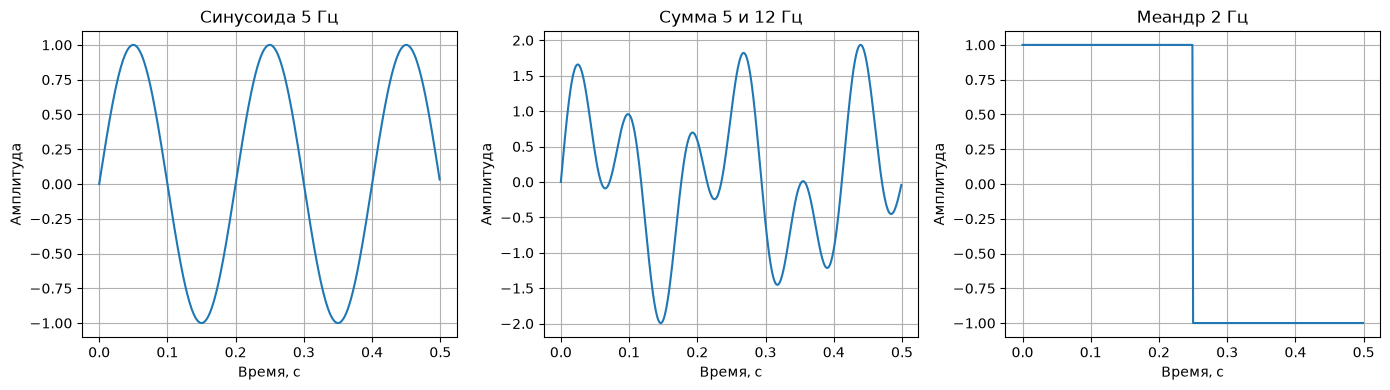

In [3]:
f1, f2 = 5, 12
sin5 = np.sin(2 * np.pi * f1 * t)
sum_sin = sin5 + np.sin(2 * np.pi * f2 * t)
meander = signal.square(2 * np.pi * 2 * t)
mask = t < 0.5

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, y, title in zip(axes, [sin5, sum_sin, meander],
                        ['Синусоида 5 Гц', 'Сумма 5 и 12 Гц', 'Меандр 2 Гц']):
    ax.plot(t[mask], y[mask])
    ax.set(title=title, xlabel='Время, с', ylabel='Амплитуда')
plt.tight_layout()
plt.show()

**Вопрос:** Изменится ли вид суммы синусоид, если одну из них сдвинуть по фазе на 90° ($\pi/2$), на 180° ($\pi$), на 360° ($2\pi$)? (Проверьте на практике, изменив фазу второго сигнала). Объясните результат.

При 90° и 180° форма суммы меняется, а при 180° вторая синусоида меняет знак. 360° — это полный оборот, приходим к ночалу

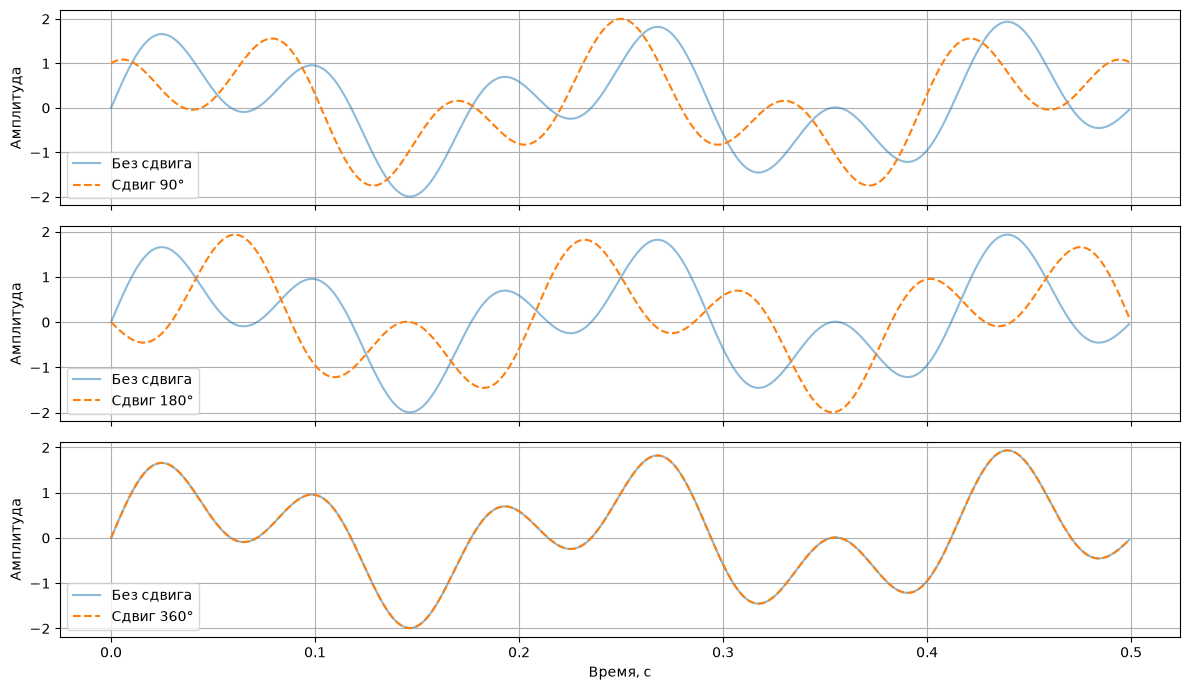

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True)
for ax, phi in zip(axes, [np.pi/2, np.pi, 2*np.pi]):
    changed = sin5 + np.sin(2*np.pi*f2*t + phi)
    ax.plot(t[mask], sum_sin[mask], alpha=0.5, label='Без сдвига')
    ax.plot(t[mask], changed[mask], '--', label=f'Сдвиг {np.degrees(phi):.0f}°')
    ax.set_ylabel('Амплитуда')
    ax.legend()
axes[-1].set_xlabel('Время, с')
plt.tight_layout()
plt.show()

## Часть 2. Спектральный анализ с помощью БПФ

### Задание 2.1. Спектр синусоиды

Для синусоиды частотой 5 Гц вычислите БПФ (`np.fft.fft`). Постройте амплитудный спектр (модуль БПФ) для положительных частот. Не забудьте правильно нормировать амплитуды (поделить на количество отсчётов и учесть, что мы берём половину спектра). Частотную ось получите с помощью `np.fft.fftfreq`.

Подпишите оси: частота (Гц), амплитуда.

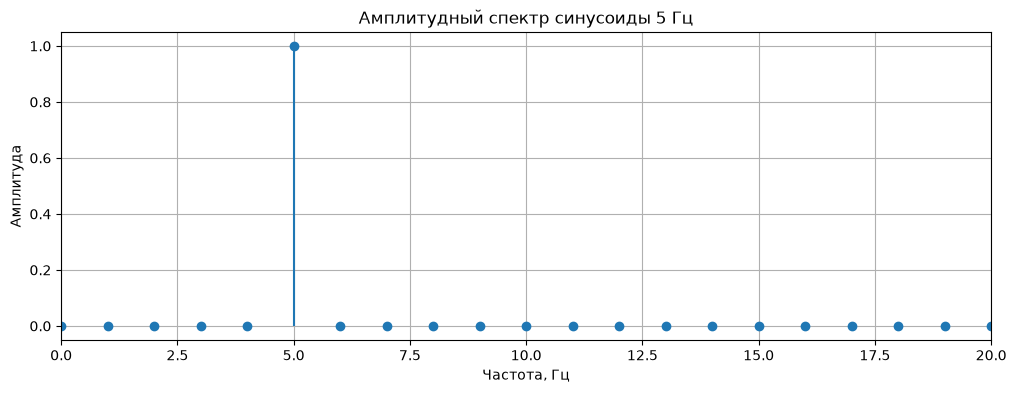

Пик: 5.0 Гц, амплитуда: 1.0


In [5]:
X = np.fft.fft(sin5)
freq = np.fft.fftfreq(len(t), d=1/fs)
half = len(t) // 2
freq_pos = freq[:half]
X_mag = 2 * np.abs(X[:half]) / len(t)
X_mag[0] /= 2  # постоянная составляющая не имеет пары

plt.stem(freq_pos, X_mag, basefmt=' ')
plt.xlim(0, 20)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда')
plt.title('Амплитудный спектр синусоиды 5 Гц')
plt.show()
print('Пик:', freq_pos[np.argmax(X_mag)], 'Гц, амплитуда:', round(X_mag.max(), 3))

**Вопрос:** Почему в спектре присутствует только один пик? Какая должна быть его амплитуда теоретически? Совпадает ли с полученной?

один пик на 5 Гц, т.к. у нас одна синусоида. Амплитуда 1, как и должна. За секунду пять периодов.

### Задание 2.2. Спектр суммы синусоид

Для суммы синусоид (5 и 12 Гц) постройте амплитудный спектр. Убедитесь, что видны два пика на ожидаемых частотах. Измерьте их амплитуды.

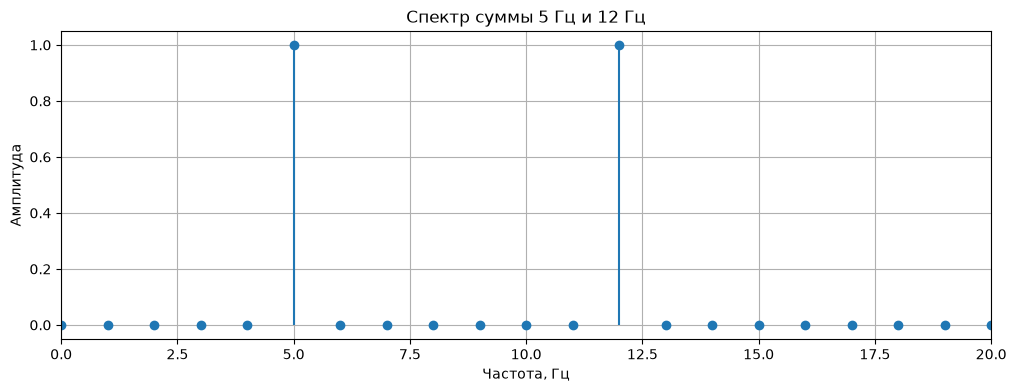

5 Гц: амплитуда 1.000000
12 Гц: амплитуда 1.000000


In [6]:
X_sum = np.fft.fft(sum_sin)
X_sum_mag = 2 * np.abs(X_sum[:half]) / len(t)
X_sum_mag[0] /= 2
plt.stem(freq_pos, X_sum_mag, basefmt=' ')
plt.xlim(0, 20)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда')
plt.title('Спектр суммы 5 Гц и 12 Гц')
plt.show()
for f in [5, 12]:
    i = np.argmin(abs(freq_pos - f))
    print(f'{f} Гц: амплитуда {X_sum_mag[i]:.6f}')

**Вопрос:** Изменится ли амплитудный спектр, если фазы сигналов изменить? Проверьте, задав для одного из них случайную фазу.

поменял фазу, высота пиков осталась та же. фаза меняет форму сигнала во времени, а не амплитуды частот. Здесь обе частоты точно попадают в сетку БПФ.

Случайная фаза: 3.216 рад
Максимальное отличие амплитуд: 6.40e-16


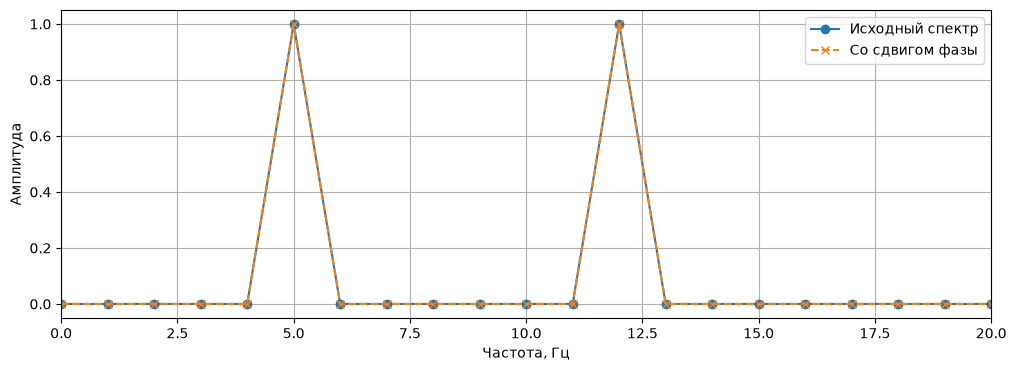

In [7]:
phi = rng.uniform(0, 2*np.pi)
shifted = sin5 + np.sin(2*np.pi*f2*t + phi)
spectrum_shifted = 2*np.abs(np.fft.fft(shifted)[:half])/len(t)
spectrum_shifted[0] /= 2
print(f'Случайная фаза: {phi:.3f} рад')
print(f'Максимальное отличие амплитуд: {np.max(abs(spectrum_shifted-X_sum_mag)):.2e}')
plt.plot(freq_pos, X_sum_mag, 'o-', label='Исходный спектр')
plt.plot(freq_pos, spectrum_shifted, 'x--', label='Со сдвигом фазы')
plt.xlim(0, 20)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда')
plt.legend()
plt.show()

### Задание 2.3. Спектр меандра

Постройте амплитудный спектр меандра частотой 2 Гц. Сравните с теоретическим представлением: меандр состоит из нечётных гармоник с убывающими амплитудами $(1, 1/3, 1/5,\dots)\cdot 4/\pi$.

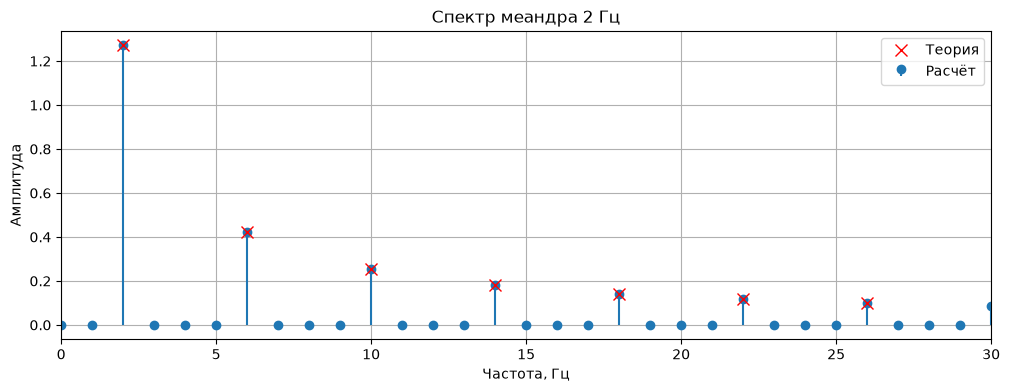

Гармоника | Частота | Теория | БПФ
        1 |       2 | 1.273240 | 1.273248
        3 |       6 | 0.424413 | 0.424438
        5 |      10 | 0.254648 | 0.254690
        7 |      14 | 0.181891 | 0.181950
        9 |      18 | 0.141471 | 0.141546


In [8]:
X_meander = np.fft.fft(meander)
X_meander_mag = 2 * np.abs(X_meander[:half]) / len(t)
X_meander_mag[0] /= 2
plt.stem(freq_pos, X_meander_mag, basefmt=' ', label='Расчёт')
harmonics = np.arange(1, 14, 2)
theory = 4 / (np.pi * harmonics)
plt.plot(2 * harmonics, theory, 'rx', ms=9, label='Теория')
plt.xlim(0, 30)
plt.xlabel('Частота, Гц')
plt.ylabel('Амплитуда')
plt.title('Спектр меандра 2 Гц')
plt.legend()
plt.show()
print('Гармоника | Частота | Теория | БПФ')
for k, expected in zip(harmonics[:5], theory[:5]):
    i = np.argmin(abs(freq_pos - 2*k))
    print(f'{k:9d} | {2*k:7d} | {expected:.6f} | {X_meander_mag[i]:.6f}')

**Вопрос:** Почему в спектре меандра присутствуют только нечётные гармоники? Покажите, что амплитуды гармоник совпадают с теоретическим значением.

У меандра вторая половина периода повторяет первую с -, поэтому гармоники сокращаются. В таблице я сравнил первые пять нечётных гармоник с $4/(\pi k)$ — значения похожи.

## Часть 3. Дискретизация и алиасинг

### Задание 3.1. Корректная и некорректная дискретизация

Создайте «аналоговый» сигнал — синусоиду частотой 8 Гц, но с очень высокой частотой дискретизации (например, 1000 Гц), чтобы он выглядел гладким.

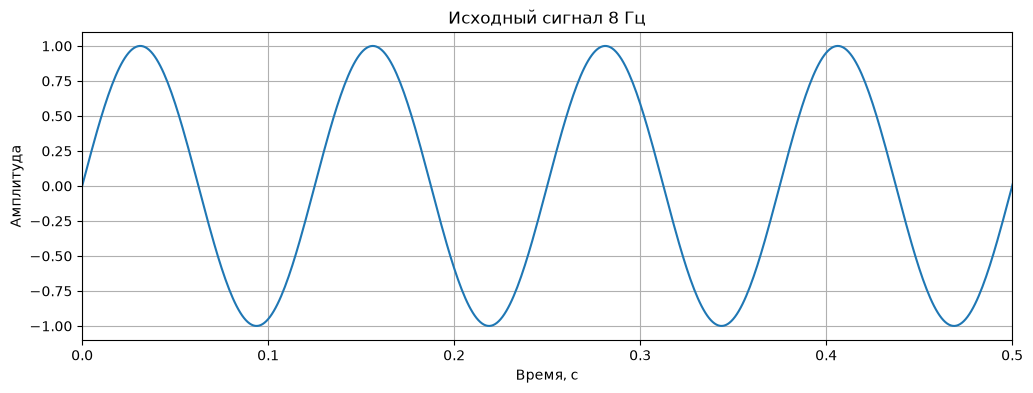

In [9]:
fs_analog = 1000
t_analog = np.arange(fs_analog) / fs_analog
f_signal = 8
analog_signal = np.sin(2 * np.pi * f_signal * t_analog)
plt.plot(t_analog, analog_signal)
plt.xlim(0, 0.5)
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Исходный сигнал 8 Гц')
plt.show()

Теперь выполните его дискретизацию с двумя разными частотами:
- $f_{s1} = 50$ Гц (заведомо больше удвоенной частоты сигнала, 2·8=16 Гц);
- $f_{s2} = 12$ Гц (меньше 16 Гц).

Для этого создайте новые временные оси с шагом $1/f_{s1}$ и $1/f_{s2}$ и вычислите значения синусоиды в этих точках.

На одном графике изобразите:
- исходный гладкий сигнал (тонкая линия);
- отсчёты при корректной дискретизации (маркеры);
- отсчёты при алиасинге (маркеры другого цвета).

Также постройте сигнал, который «воспринимается» после дискретизации с малой частотой.

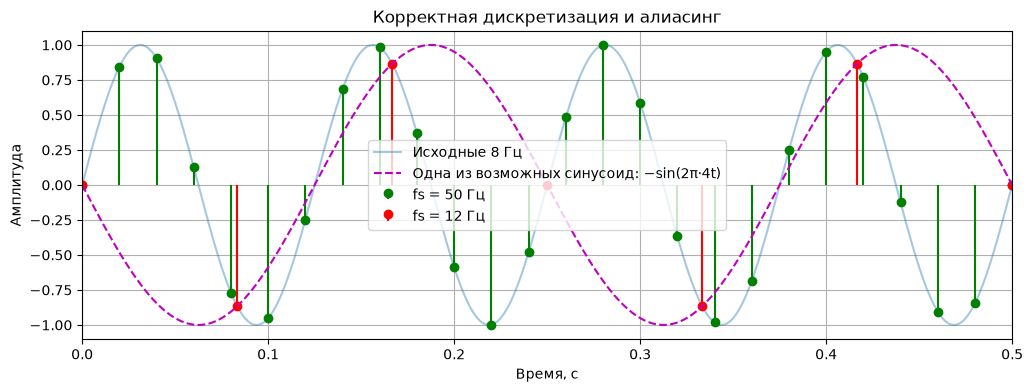

Наблюдаемая частота: 4.0 Гц


In [10]:
fs1, fs2 = 50, 12
t1 = np.arange(fs1) / fs1
t2 = np.arange(fs2) / fs2
samples1 = np.sin(2 * np.pi * f_signal * t1)
samples2 = np.sin(2 * np.pi * f_signal * t2)
f_signed = f_signal - fs2  # 8 - 12 = -4 Гц
alias_signal = np.sin(2 * np.pi * f_signed * t_analog)

plt.plot(t_analog, analog_signal, alpha=0.4, label='Исходные 8 Гц')
plt.stem(t1, samples1, linefmt='g-', markerfmt='go', basefmt=' ', label='fs = 50 Гц')
plt.stem(t2, samples2, linefmt='r-', markerfmt='ro', basefmt=' ', label='fs = 12 Гц')
plt.plot(t_analog, alias_signal, 'm--', label='Одна из возможных синусоид: −sin(2π·4t)')
plt.xlim(0, 0.5)
plt.xlabel('Время, с')
plt.ylabel('Амплитуда')
plt.title('Корректная дискретизация и алиасинг')
plt.legend()
plt.show()
print(f'Наблюдаемая частота: {abs(f_signed):.1f} Гц')

**Вопрос:** Какая частота «кажется» присутствующей в сигнале при $f_{s2}=12$ Гц? Совпадает ли она с предсказанной теоретически? (Подсказка: формула алиасинга $f_{alias} = |f - k f_s|$, выберите $k$ так, чтобы $f_{alias}$ лежала в интервале $[0, f_s/2]$.)

Получилось 4 Гц: $|8-12|=4$. Только для совпадения самих отсчётов синус нужно взять с минусом. Получается, по этим редким точкам мы уже не отличим исходные 8 Гц от такой синусоиды 4 Гц.

### Задание 3.2. Интерактивная демонстрация алиасинга

Используя `ipywidgets.interact`, создайте интерактивный график, где можно менять частоту сигнала и частоту дискретизации ползунками, и сразу видеть исходный сигнал, отсчёты и восстановленный сигнал. Пример такого кода был на лекции.

Добейтесь, чтобы при нарушении условия Найквиста явно проявлялся алиасинг (восстановленный сигнал имел более низкую частоту, чем исходный).

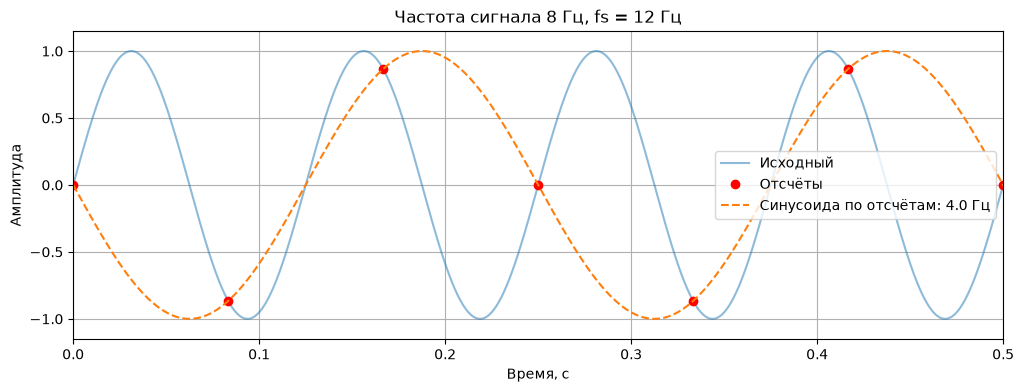

interactive(children=(IntSlider(value=20, description='f_signal', max=40, min=1), IntSlider(value=52, descript…

<function __main__.plot_aliasing(f_signal, f_sampling)>

In [11]:
def plot_aliasing(f_signal, f_sampling):
    tt = np.arange(2000) / 2000
    ts = np.arange(0, 1, 1/f_sampling)
    f_alias_signed = (f_signal + f_sampling/2) % f_sampling - f_sampling/2
    plt.figure(figsize=(12, 4))
    plt.plot(tt, np.sin(2*np.pi*f_signal*tt), alpha=0.5, label='Исходный')
    plt.plot(ts, np.sin(2*np.pi*f_signal*ts), 'ro', label='Отсчёты')
    plt.plot(tt, np.sin(2*np.pi*f_alias_signed*tt), '--',
             label=f'Синусоида по отсчётам: {abs(f_alias_signed):.1f} Гц')
    plt.xlim(0, 0.5)
    plt.ylim(-1.15, 1.15)
    plt.xlabel('Время, с')
    plt.ylabel('Амплитуда')
    plt.title(f'Частота сигнала {f_signal:g} Гц, fs = {f_sampling:g} Гц')
    plt.legend()
    plt.show()

plot_aliasing(8, 12)
widgets.interact(plot_aliasing, f_signal=(1, 40, 1), f_sampling=(5, 100, 1))

**Вопрос:** При каких соотношениях частоты сигнала и частоты дискретизации алиасинг наиболее заметен? Что происходит, когда частота сигнала в точности равна половине частоты дискретизации?

Алиасинг появляется, когда $f_s<2f$. На ползунках это хорошо видно: исходная частота растёт, а по отсчётам мы иногда получаем совсем медленную волну. Ровно на границе $f_s=2f$ тоже есть проблема: синус с нулевой фазой может дать одни нули. Поэтому лучше брать частоту с запасом.

## Вывод

разобрался, как строить сигнал и его спектр. По БПФ удобно смотреть, какие частоты у нас есть, а при редкой дискретизации можно получить совсем другую частоту.